# Evaluating a Shakespeare RAG Chatbot

This notebook backs up my Shakespeare chatbot, a RAG (Retrieval-Augmented Generation) app that answers questions about Shakespeare's works with a local LLM. The app itself lives in the Python files of this folder (`split_text.py`, `fill_db.py`, `chat.py`, `app.py`). In this notebook, I look at the data it searches and I measure how well it finds the right passages.

**A note on AI use:** This notebook has been generated step by step with the help of AI, to measure the retrieval performance of the RAG for specific questions

## Context

Its pipeline:

1. `split_text.py` cuts the text into chunks, then `fill_db.py` gives each chunk its act and scene, turns it into an embedding with a small local model (`all-MiniLM-L6-v2`) and stores everything in a ChromaDB vector database.
   
2. `chat.py` takes a question, finds the closest related chunks, and sends them to an LLM with instructions to answer only from these passages. It uses a local model (Ministral 3B or Gemma, through LM Studio), or Claude Haiku through the Anthropic API for computers that cannot run a local model.

With 44 works instead of one, finding the right passage gets much harder, so I added:

- **play detection**: when a question names a play or a character ("Why does Iago hate Othello?"), the search stays in that play,
- **hybrid search**: the semantic search with embeddings is combined with a lexical search (BM25) that finds exact words, using Reciprocal Rank Fusion,
- **neighbouring chunks**: each chunk found comes with the chunk before and after it, to give the LLM the rest of the dialogue as context.

## Goal of this Notebook

Measure, on a set of test questions, how often the passage that answers the question is among the passages sent to the LLM, and check whether each of the additions above really helps.

This notebook evaluates the **retrieval** step only. The answers of the LLM are not graded here.

## Plan

1. Setup
2. Load and inspect the works and the chunks
3. Explore the chunk lengths
4. Check the play detection
5. Evaluate the retrieval
6. Conclusion

## 1. Setup

The notebook imports the functions of the app itself, so it evaluates exactly the code the chatbot runs. `import chat` loads the embedding model, the ChromaDB database and the BM25 index, so `python fill_db.py` must have been run once before.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import split_text
import fill_db
import chat

N_CHUNKS = 8 # default number of chunks in the chatbot
TOKEN_LIMIT = chat.embedding_model.max_seq_length # MiniLM only reads the first 256 tokens of a text
TYPE_COLORS = {"play": "#2a78d6", "poetry": "#eb6834"}

/Users/clem2barbeyrac/Desktop/Codex Projects/datascience-portfolio/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1114 11:42:59.588000 41092 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2970.67it/s]


## 2. Load and inspect the works and the chunks

I run the same steps as `fill_db.py` (with the functions of `split_text.py`), without the embedding: load the text, split it into works, then cut each work into chunks with their metadata.

In [2]:
text = split_text.load_text()
works = split_text.split_into_works(text)
texts, ids, metadatas, catalogue = fill_db.build_metadata(works)

chunks_df = pd.DataFrame(metadatas) # one row per chunk with its work, type, act, scene
chunks_df["length"] = [len(chunk) for chunk in texts] # number of characters of each chunk
chunks_df.head()

Works found: 44
Total chunks: 12499


,source,chunk_id,work,type,act,scene,section,length
0,Project Gutenberg #100,0,The Sonnets,poetry,,,Sonnet 1,618
1,Project Gutenberg #100,1,The Sonnets,poetry,,,Sonnet 2,635
2,Project Gutenberg #100,2,The Sonnets,poetry,,,Sonnet 3,613
3,Project Gutenberg #100,3,The Sonnets,poetry,,,Sonnet 4,590
4,Project Gutenberg #100,4,The Sonnets,poetry,,,Sonnet 5,625


In [3]:
print("Chunks in this notebook:", len(chunks_df))
print("Chunks in the ChromaDB database:", chat.collection.count())
print()
print(chunks_df.drop_duplicates("work")["type"].value_counts())

Chunks in this notebook: 12499
Chunks in the ChromaDB database: 12499

type
play      38
poetry     6
Name: count, dtype: int64


In [4]:
# a few random chunks, to see what the LLM receives
for chunk, meta in zip(texts[5000:5002], metadatas[5000:5002]):
    print(f"--- {meta['work']}, {meta['section']}")
    print(chunk)

--- The Tragedy of Julius Caesar, Act III, Scene II
ANTONY.
I thrice presented him a kingly crown,
Which he did thrice refuse. Was this ambition?
Yet Brutus says he was ambitious;
And sure he is an honourable man.
I speak not to disprove what Brutus spoke,
But here I am to speak what I do know.
You all did love him once, not without cause;
What cause withholds you then to mourn for him?
O judgment, thou art fled to brutish beasts,
And men have lost their reason. Bear with me.
My heart is in the coffin there with Caesar,
And I must pause till it come back to me.
--- The Tragedy of Julius Caesar, Act III, Scene II
FIRST CITIZEN.
Methinks there is much reason in his sayings.

SECOND CITIZEN.
If thou consider rightly of the matter,
Caesar has had great wrong.

THIRD CITIZEN.
Has he, masters?
I fear there will a worse come in his place.


- The file splits into 44 works: 38 plays and 6 works of poetry (the Sonnets and 5 poems), as listed in its table of contents.
- There are 12,499 chunks, the same number as in the ChromaDB database, so the database matches the current code.
- A chunk is mostly one speech with its speaker name at the top, and it keeps its work, act and scene. Poems get their number instead ("Sonnet 1").

## 3. Explore the chunks

### 3.1 Chunks per work

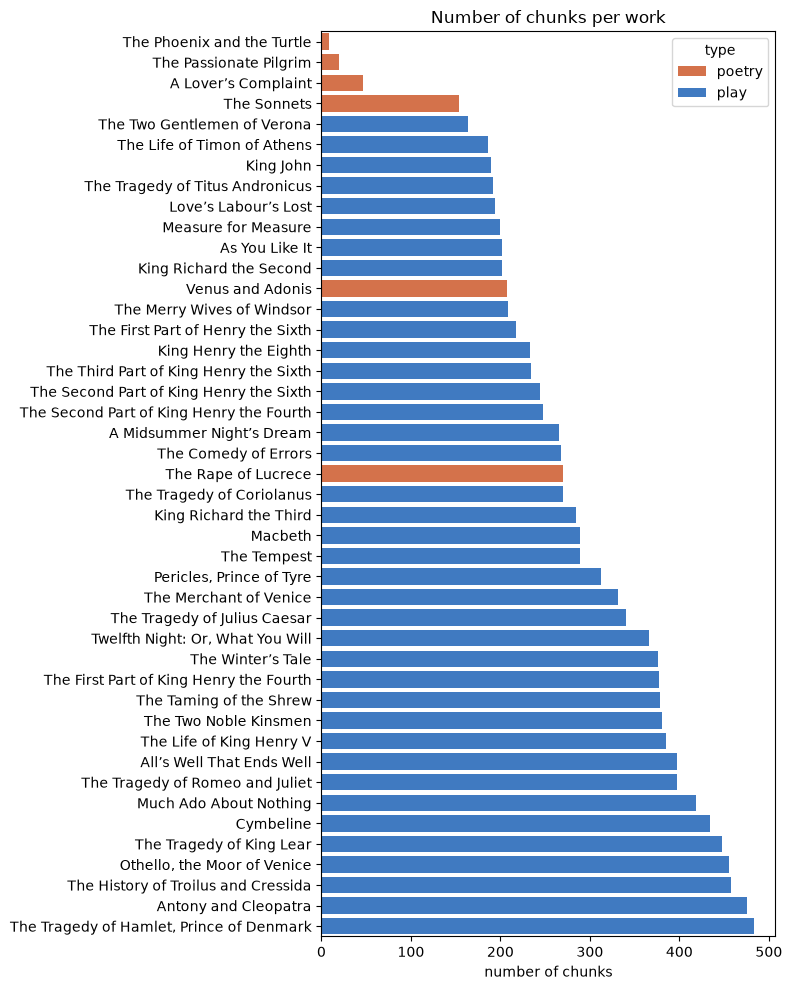

In [5]:
chunks_per_work = chunks_df.groupby(["work", "type"]).size().reset_index(name="chunks").sort_values("chunks")

plt.figure(figsize=(8, 10))
sns.barplot(data=chunks_per_work, x="chunks", y="work", hue="type", palette=TYPE_COLORS, dodge=False)
plt.title("Number of chunks per work")
plt.xlabel("number of chunks")
plt.ylabel("")
plt.legend(title="type")
plt.tight_layout()
plt.show()

A play has a median of 289 chunks. Hamlet is the longest work (483 chunks) and The Phoenix and the Turtle the shortest (8). The plays make up most of the database, so a search in all works mostly meets play passages, and one play is only a small part of it. This is why the chatbot searches inside the play when it can detect it (section 4).

### 3.2 Chunk length and the 256-token limit

The embedding model reads at most 256 tokens of a text. A token is a word or a piece of a word: in this text a token is about 4 characters, so 256 tokens is about 1,000 characters. Everything after is ignored, so the end of a long speech could never be found by the semantic search.

The original chunking only had a minimum length (`MIN_LENGTH = 200` characters). I added a maximum (`MAX_LENGTH = 800`): a longer chunk is cut into equal pieces between two lines of verse. To see the effect, I run the chunking again without the maximum, by setting it very high for one cell.

In [6]:
split_text.MAX_LENGTH = 1_000_000 # no maximum, like the original chunking
chunks_without_max = []
for work in works:
    chunks_without_max += split_text.chunk_text(work["text"])
split_text.MAX_LENGTH = 800 # back to the value of the app

# number of tokens of each chunk, counted with the tokenizer of the embedding model
tokens_without_max = [len(chat.embedding_model.tokenizer(chunk)["input_ids"]) for chunk in chunks_without_max]
tokens_with_max = [len(chat.embedding_model.tokenizer(chunk)["input_ids"]) for chunk in texts]

token_counts = pd.DataFrame({
    "chunking": ["without maximum"] * len(tokens_without_max) + ["with MAX_LENGTH = 800"] * len(tokens_with_max),
    "tokens": tokens_without_max + tokens_with_max
})
token_counts.groupby("chunking")["tokens"].agg(
    chunks="size",
    median_tokens="median",
    over_limit=lambda tokens: (tokens > TOKEN_LIMIT).sum()
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (280 > 256). Running this sequence through the model will result in indexing errors


,chunks,median_tokens,over_limit
chunking,,,
with MAX_LENGTH = 800,12499,100.0,0
without maximum,9713,82.0,906


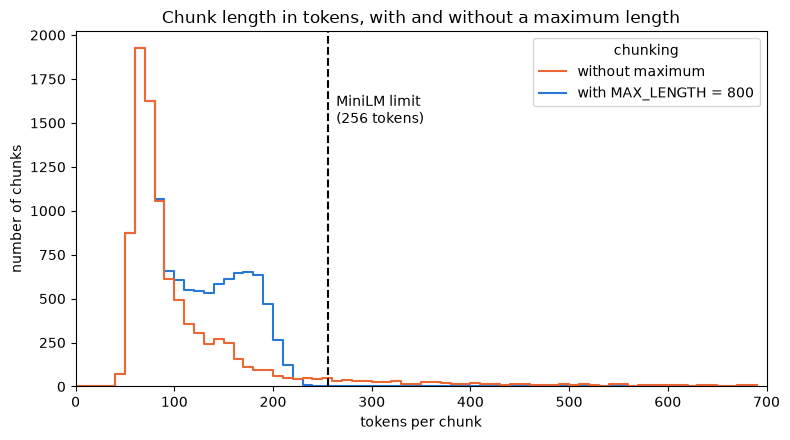

In [7]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=token_counts, x="tokens", hue="chunking", bins=range(0, 700, 10), element="step", fill=False, linewidth=1.5,
             palette=["#eb6834", "#2a78d6"])
plt.axvline(TOKEN_LIMIT, color="black", linestyle="--") # the limit of the embedding model
plt.text(TOKEN_LIMIT + 8, 1500, "MiniLM limit\n(256 tokens)")
plt.title("Chunk length in tokens, with and without a maximum length")
plt.xlabel("tokens per chunk")
plt.ylabel("number of chunks")
plt.xlim(0, 700)
plt.tight_layout()
plt.show()

- Without a maximum, 906 chunks out of 9,713 (9%) are over 256 tokens: their end is invisible to the semantic search.
- With `MAX_LENGTH = 800`, no chunk is over the limit. The long speeches are cut into pieces (the blue bump between 100 and 220 tokens), so there are more chunks: 12,499 instead of 9,713.
- The short chunks do not change: both curves are the same below 90 tokens, and the median only goes from 82 to 100 tokens.

## 4. Check the play detection

`chat.detect_works()` looks for work titles and character names in the question. The names come from the speaker lines of each play (`IAGO.`), and three rules remove the names that would give false matches:

- a name made only of common words (`LADY`, `FIRST CITIZEN`, `SAY`) is dropped, because these words are found in many questions,
- a name written in the text of more than 10 works (`ROMAN`, `CAESAR`) is dropped, because it is used as an ordinary word or a reference to history,
- a name that speaks in more than 3 plays (`YORK`, `ANTONIO`) is ignored, because it does not tell which play the question is about.

In [8]:
names_df = pd.DataFrame({
    "name": list(catalogue["characters"].keys()),
    "plays": [len(plays) for plays in catalogue["characters"].values()]
})
print("Character names kept:", len(names_df))
print("Names found in at most 3 plays:", (names_df["plays"] <= chat.MAX_WORKS_PER_NAME).sum())
names_df.sort_values("plays", ascending=False).head(5)

Character names kept: 587
Names found in at most 3 plays: 577


,name,plays
164,GLOUCESTER,6
172,YORK,6
168,KING HENRY,5
136,WARWICK,5
219,PETER,5


To test the detection and the retrieval, I wrote 39 questions in modern English. For each question I give the work that answers it and a short **evidence** quote from the text: the passage that answers the question contains this quote.

- 28 questions are **named**: they name a character or a work ("What does Lady Macbeth do when she sleepwalks?").
- 11 questions are **unnamed**: they name nobody, so the search must look in all the works ("Who says 'To be, or not to be'?").

In [9]:
questions_df = pd.read_csv("data/eval_questions.csv")
print(questions_df["question_type"].value_counts())
questions_df.head()

question_type
named      28
unnamed    11
Name: count, dtype: int64


,question,expected_work,evidence,question_type
0,Why does Iago hate Othello?,"Othello, the Moor of Venice",I hate the Moor,named
1,What does Lady Macbeth do when she sleepwalks?,Macbeth,"Out, damned spot",named
2,What does Portia say about mercy during the tr...,The Merchant of Venice,quality of mercy,named
3,How does Romeo describe Juliet when he sees he...,The Tragedy of Romeo and Juliet,what light through yonder,named
4,What do the witches predict for Macbeth?,Macbeth,"All hail, Macbeth",named


In [10]:
questions_df["detected_works"] = [chat.detect_works(question) for question in questions_df["question"]]

# the detection is right when it finds the expected work, wrong when it finds only other works, and empty when it finds nothing
detection_result = []
for expected, detected in zip(questions_df["expected_work"], questions_df["detected_works"]):
    if not detected:
        detection_result.append("nothing detected (all works)")
    elif expected in detected:
        detection_result.append("expected work detected")
    else:
        detection_result.append("wrong work")
questions_df["detection"] = detection_result

pd.crosstab(questions_df["question_type"], questions_df["detection"])

detection,expected work detected,nothing detected (all works)
question_type,,
named,27,1
unnamed,0,11


In [11]:
# questions where the detection found more than one work, or not the expected one
questions_df.loc[(questions_df["detected_works"].str.len() > 1) | (questions_df["detection"] == "wrong work"),
                 ["question", "expected_work", "detected_works"]]

,question,expected_work,detected_works
2,What does Portia say about mercy during the tr...,The Merchant of Venice,"[The Tragedy of Julius Caesar, The Merchant of..."
3,How does Romeo describe Juliet when he sees he...,The Tragedy of Romeo and Juliet,"[Measure for Measure, The Tragedy of Romeo and..."
9,How does Juliet die?,The Tragedy of Romeo and Juliet,"[Measure for Measure, The Tragedy of Romeo and..."
10,How does Puck describe himself to the fairy?,A Midsummer Night’s Dream,"[The Merry Wives of Windsor, A Midsummer Night..."
14,What does Falstaff think about honour?,The First Part of King Henry the Fourth,"[The First Part of King Henry the Fourth, The ..."
16,Why does Brutus decide that Caesar must die?,The Tragedy of Julius Caesar,"[The Tragedy of Coriolanus, The Tragedy of Jul..."
24,What does Mark Antony say to the crowd at Caes...,The Tragedy of Julius Caesar,"[Antony and Cleopatra, The Tragedy of Julius C..."


- 27 of the 28 named questions find their expected work. The one that fails is about Venus and Adonis: poems have no speakers, so only the full title can be detected, and the question does not use it.
- No question is sent to a wrong work, and the 11 unnamed questions go to all works, as they should. Before I added the rule on names written in many works, "a Roman leader" was sent to Titus Andronicus, where a speaker is called "A Roman".
- 7 questions get several works because a name is shared ("Portia" in Julius Caesar and The Merchant of Venice, "Juliet" in Measure for Measure and Romeo and Juliet). The expected work is always among them, so the search only covers one or two more plays.

## 5. Evaluate the retrieval

### 5.1 The metric

For each question, a retrieval is a **hit** when one of the passages sent to the LLM contains the evidence quote. The **hit rate** is the share of questions with a hit. It does not tell if the final answer is good, but without the right passage the LLM cannot answer from the text.

ChromaDB finds the closest chunks with an approximate method to go faster. With its default precision, the results changed slightly from one run to the next, so `fill_db.py` sets a higher precision (`ef_search = 1000`): the numbers below are the same at every run.

I compare five versions, adding one change at a time, all with 8 chunks:

1. **semantic only**: embeddings search in all works (the original approach on the complete works),
2. **+ play detection**: same, but in the detected works,
3. **BM25 only** (with play detection): lexical search alone, to compare,
4. **hybrid**: semantic and BM25 merged with Reciprocal Rank Fusion,
5. **hybrid + neighbours**: the version of the app, with the chunks before and after each chunk found.

In [12]:
versions = [
    {"version": "1. semantic only", "detection": False, "method": "semantic", "neighbours": False},
    {"version": "2. + play detection", "detection": True, "method": "semantic", "neighbours": False},
    {"version": "3. BM25 only", "detection": True, "method": "lexical", "neighbours": False},
    {"version": "4. hybrid", "detection": True, "method": "hybrid", "neighbours": False},
    {"version": "5. hybrid + neighbours", "detection": True, "method": "hybrid", "neighbours": True},
]

results = [] # one row per version and question
for version in versions:
    for question, evidence, question_type in zip(questions_df["question"], questions_df["evidence"], questions_df["question_type"]):
        works = chat.detect_works(question) if version["detection"] else []
        passages = chat.search_chunks(question, works, N_CHUNKS, method=version["method"])
        if version["neighbours"]:
            passages = chat.add_neighbours(passages)
        hit = any(evidence in passage["text"] for passage in passages)
        results.append({"version": version["version"], "question": question, "question_type": question_type, "hit": hit})

results_df = pd.DataFrame(results)
hit_rates = results_df.pivot_table(index="version", columns="question_type", values="hit", aggfunc="mean")
hit_rates["all"] = results_df.groupby("version")["hit"].mean()
hit_rates.round(2)

question_type,named,unnamed,all
version,,,
1. semantic only,0.18,0.45,0.26
2. + play detection,0.46,0.45,0.46
3. BM25 only,0.46,0.55,0.49
4. hybrid,0.36,0.55,0.41
5. hybrid + neighbours,0.64,0.55,0.62


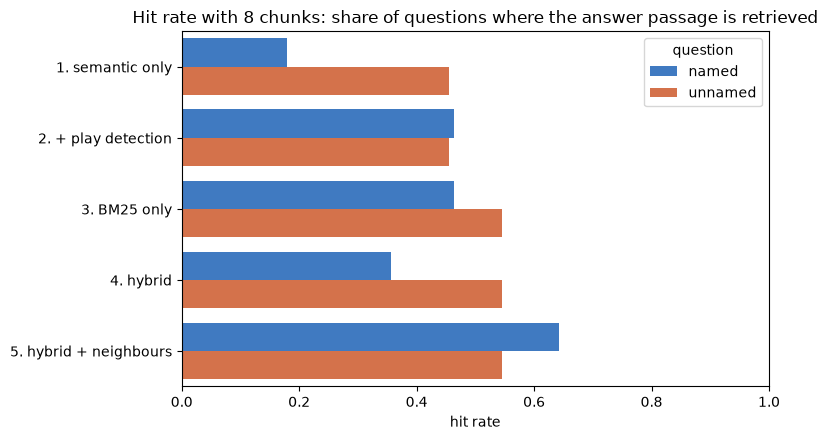

In [13]:
plt.figure(figsize=(8, 4.5))
sns.barplot(data=results_df, x="hit", y="version", hue="question_type", errorbar=None,
            palette={"named": "#2a78d6", "unnamed": "#eb6834"})
plt.title(f"Hit rate with {N_CHUNKS} chunks: share of questions where the answer passage is retrieved")
plt.xlabel("hit rate")
plt.ylabel("")
plt.xlim(0, 1)
plt.legend(title="question")
plt.tight_layout()
plt.show()

- Play detection is the biggest single step: on named questions the hit rate goes from 0.18 to 0.46 (from 5 to 13 questions out of 28). In all works, the speech that answers a question about Iago competes with 12,000 other chunks.
- The unnamed questions do not change with detection (0.45 in both versions), as expected since nothing is detected for them.
- With 8 chunks, the hybrid search alone (16 questions) is not better than the semantic search (18) or BM25 (19): the fusion keeps about 4 chunks of each search, and loses some good chunks of both.
- The neighbours bring the largest gain on top of it: from 16 to 24 questions. The quote is often in the speech just before or after the chunk found.
- With 39 questions, a difference of one or two questions is not meaningful.

### 5.2 Number of chunks

The sidebar of the app lets the user choose between 3 and 20 chunks. More chunks give more chances to include the right passage, but a longer prompt for a small LLM. I compare the three search methods (all with play detection and neighbours) for 4, 8, 12 and 20 chunks.

In [14]:
chunk_numbers = [4, 8, 12, 20]
methods = {"semantic": "semantic only", "lexical": "BM25 only", "hybrid": "hybrid"}

curve = [] # one row per method, number of chunks and question
for method, method_name in methods.items():
    for n_chunks in chunk_numbers:
        for question, evidence in zip(questions_df["question"], questions_df["evidence"]):
            passages = chat.add_neighbours(chat.search_chunks(question, chat.detect_works(question), n_chunks, method=method))
            curve.append({"method": method_name, "n_chunks": n_chunks, "hit": any(evidence in passage["text"] for passage in passages)})

curve_df = pd.DataFrame(curve)
curve_df.pivot_table(index="n_chunks", columns="method", values="hit", aggfunc="sum")

method,BM25 only,hybrid,semantic only
n_chunks,,,
4,18,18,20
8,23,24,24
12,26,27,25
20,29,32,28


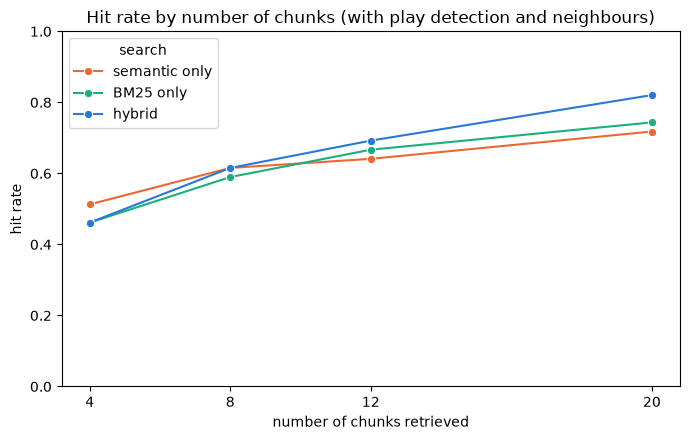

In [15]:
plt.figure(figsize=(7, 4.5))
sns.lineplot(data=curve_df, x="n_chunks", y="hit", hue="method", marker="o", errorbar=None,
             palette={"semantic only": "#eb6834", "BM25 only": "#1baf7a", "hybrid": "#2a78d6"})
plt.title("Hit rate by number of chunks (with play detection and neighbours)")
plt.xlabel("number of chunks retrieved")
plt.ylabel("hit rate")
plt.xticks(chunk_numbers)
plt.ylim(0, 1)
plt.legend(title="search")
plt.tight_layout()
plt.show()

- More chunks always help: with the hybrid search, from 18 questions with 4 chunks to 32 with 20 chunks.
- Up to 12 chunks the three searches are close (25 to 27 questions at 12). At 20 chunks the hybrid search finds 32 questions, against 29 for BM25 and 28 for the semantic search: the two searches find different passages, and the fusion keeps both.
- The app uses 8 chunks by default (24 questions). 12 chunks would find 3 more questions here, but with the neighbours it can send around 36 chunks to the LLM, which may not fit in the context length set for a small model in LM Studio. I keep 8 as the default and the user can move the slider.

### 5.3 Which questions still fail?

The questions where the app version (hybrid, neighbours, 8 chunks) does not find the passage:

In [16]:
final_results = results_df[results_df["version"] == "5. hybrid + neighbours"].merge(questions_df[["question", "expected_work", "evidence", "detection"]], on="question")
final_results.loc[~final_results["hit"], ["question", "expected_work", "evidence", "detection"]]

,question,expected_work,evidence,detection
0,Why does Iago hate Othello?,"Othello, the Moor of Venice",I hate the Moor,expected work detected
1,What does Lady Macbeth do when she sleepwalks?,Macbeth,"Out, damned spot",expected work detected
4,What do the witches predict for Macbeth?,Macbeth,"All hail, Macbeth",expected work detected
5,How does Shylock argue that Jews are human lik...,The Merchant of Venice,Hath not a Jew eyes,expected work detected
12,How does Lear react to Cordelia's death?,The Tragedy of King Lear,"Howl, howl",expected work detected
16,Why does Brutus decide that Caesar must die?,The Tragedy of Julius Caesar,It must be by his death,expected work detected
19,Why does Viola decide to disguise herself?,"Twelfth Night: Or, What You Will",Conceal me what I am,expected work detected
21,What does Macbeth say when he hears that his w...,Macbeth,"Tomorrow, and tomorrow",expected work detected
24,What does Mark Antony say to the crowd at Caes...,The Tragedy of Julius Caesar,lend me your ears,expected work detected
25,What does Cleopatra mean by her salad days?,Antony and Cleopatra,My salad days,expected work detected


15 questions still fail: 10 named and 5 unnamed. Most of them ask about a famous line in other words ("What does Macbeth say when he hears that his wife is dead?" for "Tomorrow, and tomorrow"). The question and the line share almost no words, and MiniLM, a small model trained on modern English, does not link their meaning. The unnamed quote questions like "To be, or not to be" probably fail for another reason: the quote is made of very common words, which BM25 gives little weight.

## 6. Conclusion

The hit rate of each version, with 8 chunks:

In [17]:
summary = hit_rates.copy()
summary["questions found (out of 39)"] = results_df.groupby("version")["hit"].sum()
summary.round(2)

question_type,named,unnamed,all,questions found (out of 39)
version,,,,
1. semantic only,0.18,0.45,0.26,10
2. + play detection,0.46,0.45,0.46,18
3. BM25 only,0.46,0.55,0.49,19
4. hybrid,0.36,0.55,0.41,16
5. hybrid + neighbours,0.64,0.55,0.62,24


**What the results show**

- The complete works are split into 44 works and 12,499 chunks, all under the 256-token limit of the embedding model (906 chunks were over it without a maximum length).
- Each addition to the original pipeline was measured. Play detection and neighbouring chunks bring the largest gains: with 8 chunks, the app finds the answer passage for 24 of the 39 questions, against 10 for the original semantic search applied to all works.
- The hybrid search is as good as the semantic search with 8 chunks (24 questions each), and better with more chunks (32 against 28 with 20 chunks). I keep it because it does not lose anything here and it can find exact names and quotes that the embeddings miss.
- During development I also tested adding the work, act and scene before each chunk before embedding. It lowered the semantic search from 17 to 12 questions (not rerun in this notebook), so I did not keep it. The code stays commented out in `fill_db.py`.

**Limits**

- 39 questions is a small test set: a difference of one or two questions is not meaningful, and real users may ask easier or harder questions.
- The metric checks one exact quote. A question can have other good passages (a later scene that retells the same event), which count as misses.
- Only the retrieval is evaluated. The answers of the LLM are not graded. It would need an LLM running and a grader LLM, for prompt evaluation workflow. This is the next step.
- The play detection depends on the speaker names: it misses characters who never speak (Yorick), the poems, and short forms of a title ("Richard III").
- MiniLM is a small model trained on modern English. It often misses the meaning of Early Modern English lines, which causes most of the remaining failures.